# Clase 4 — Trama LoRa con payload de 10 bytes: hola mundo

Copia de la clase 4 con el mensaje ASCII **`hola mundo`**: 10 caracteres contando el espacio, 10 símbolos de 8 bits y 80 bits de payload. Conservamos los 8 upchirps y los 2¼ downchirps, detectamos el inicio, recuperamos el mensaje completo y medimos PER con **10 000 paquetes por SNR**.

Usamos el modelo discreto de las ecuaciones (2) y (3) de Vangelista, *Frequency Shift Chirp Modulation: The LoRa Modulation*. La función de correlación paso a paso se conserva; la variante rápida se usa únicamente para las repeticiones de PER.


In [1]:
# Cargamos las herramientas de simulación y las funciones de las clases anteriores.
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn, demodular_simbolo, modular_simbolo,
    parametros_ruido_desde_snr, validar_simbolos,
)

## 1. Parámetros y mensaje ASCII

Usamos $SF=8$, $N=2^{SF}=256$ y $B=125$ kHz, con muestreo a $B$. Cada símbolo dura $T_s=N/B=2{,}048$ ms. Cada carácter de `hola mundo`, incluido el espacio, ocupa un byte y se transmite como un chirp de `N` muestras: **10 símbolos, 80 bits y 2560 muestras de payload**.

El receptor conoce la longitud de 10 bytes para recortar el mensaje; esta trama didáctica todavía no transmite un encabezado de longitud.


In [2]:
# Un byte por carácter; mantenemos SF=8, aunque el mensaje tenga 10 símbolos.
B = 125_000
mensaje = 'hola mundo'
payload_transmitido = mensaje.encode('ascii')
cantidad_caracteres = len(payload_transmitido)
assert cantidad_caracteres == 10, 'En esta copia usamos un mensaje ASCII de 10 bytes'
valores_ascii = list(payload_transmitido)
bits_payload = [f'{valor:08b}' for valor in valores_ascii]
# El helper admite por defecto hasta 5 símbolos; aquí habilitamos los 10 solicitados.
SF = validar_simbolos(bits_payload, max_simbolos=10)
N = 2**SF
Ts = N / B
k = np.arange(N)
longitud_payload = cantidad_caracteres * N

print(f'Mensaje: {mensaje!r} | {cantidad_caracteres} bytes | {8*cantidad_caracteres} bits')
print(f'SF={SF} | chirp={N} muestras | Ts={Ts*1e3:.3f} ms')
print('Posición  Carácter  ASCII  Bits')
for posicion, (caracter, valor, bits) in enumerate(zip(mensaje, valores_ascii, bits_payload)):
    print(f'{posicion:8d}  {caracter!r:7}  {valor:5d}  {bits}')


Mensaje: 'hola mundo' | 10 bytes | 80 bits
SF=8 | chirp=256 muestras | Ts=2.048 ms
Posición  Carácter  ASCII  Bits
       0  'h'        104  01101000
       1  'o'        111  01101111
       2  'l'        108  01101100
       3  'a'         97  01100001
       4  ' '         32  00100000
       5  'm'        109  01101101
       6  'u'        117  01110101
       7  'n'        110  01101110
       8  'd'        100  01100100
       9  'o'        111  01101111


## 2. Construcción y visualización de la trama

La trama contiene **8 upchirps + 2¼ downchirps + 10 símbolos de payload**. Cada byte selecciona su propio chirp, sin modificar la cantidad de muestras por símbolo:

$$c_s[k]=\frac{1}{\sqrt{N}}e^{j2\pi[((s+k)\bmod N)k/N]},\qquad k=0,\ldots,N-1.$$

El upchirp usa $s=0$ y el downchirp es su conjugado. Concatenamos los 10 chirps del mensaje en el orden de sus caracteres. Este modelo de clase no incluye palabra de sincronización, codificación, encabezado ni CRC.


In [3]:
# Los helpers modulan los 10 bytes; el preámbulo y los downchirps se conservan.
upchirp_cero = np.exp(1j * 2 * np.pi * k**2 / N) / np.sqrt(N)
downchirp_cero = np.conj(upchirp_cero)
simbolos_payload = np.array([modular_simbolo(valor, k, N) for valor in valores_ascii])
payload_modulado = simbolos_payload.ravel()
preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.concatenate((downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]))
trama_transmitida = np.concatenate((preambulo, sincronizacion, payload_modulado))
recibida_ideal = trama_transmitida.copy()
limites = np.array([0, 8*N, 10*N, 10*N + N//4, 10*N + N//4 + longitud_payload])
assert simbolos_payload.shape == (cantidad_caracteres, N)
assert len(recibida_ideal) == limites[-1] == 5184
assert np.isclose(np.vdot(upchirp_cero, upchirp_cero).real, 1)
print(f'Trama: {len(preambulo)} de preámbulo + {len(sincronizacion)} de downchirps'
      f' + {longitud_payload} de payload = {len(recibida_ideal)} muestras'
      f' ({len(recibida_ideal)/B*1e3:.3f} ms)')


Trama: 2048 de preámbulo + 576 de downchirps + 2560 de payload = 5184 muestras (41.472 ms)


Graficamos la parte real de la señal y el índice modular de la rampa. Los colores separan preámbulo, downchirps y payload; las etiquetas del payload muestran cada carácter, incluido `' '` para el espacio.


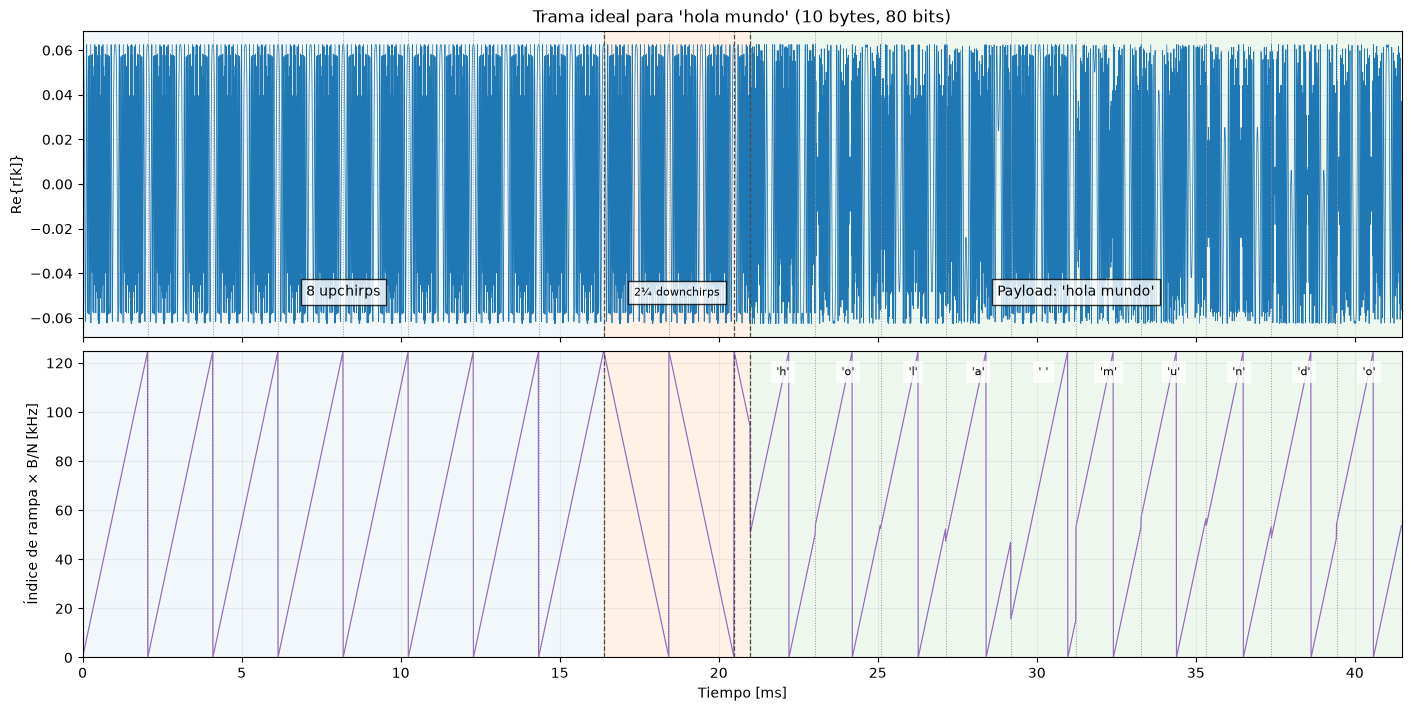

In [4]:
# Unimos las rampas de los 10 caracteres en el mismo orden que sus chirps.
rampa_up = k * B / N
rampa_down = B - rampa_up
rampa_payload = np.concatenate([np.mod(valor + k, N) * B / N for valor in valores_ascii])
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N//4], rampa_payload))
assert len(rampa_trama) == len(recibida_ideal)
tiempo_ms = np.arange(len(recibida_ideal)) / B * 1e3

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, recibida_ideal.real, lw=0.55, color='tab:blue')
axes[0].set(ylabel='Re{r[k]}', title=f'Trama ideal para {mensaje!r} (10 bytes, 80 bits)')
axes[1].plot(tiempo_ms, rampa_trama / 1e3, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]')

for ax in axes:
    ax.axvspan(0, limites[1]/B*1e3, color='tab:blue', alpha=0.06)
    ax.axvspan(limites[1]/B*1e3, limites[3]/B*1e3, color='tab:orange', alpha=0.10)
    ax.axvspan(limites[3]/B*1e3, limites[4]/B*1e3, color='tab:green', alpha=0.08)
    for muestra in np.r_[np.arange(N, 10*N, N),
                          limites[3] + np.arange(1, cantidad_caracteres)*N]:
        ax.axvline(muestra/B*1e3, color='0.6', ls=':', lw=0.7)
    for muestra in limites[1:-1]:
        ax.axvline(muestra/B*1e3, color='0.3', ls='--', lw=0.9)
    ax.grid(True, alpha=0.2)

axes[0].text(limites[1]/(2*B)*1e3, -0.05, '8 upchirps', ha='center',
             bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[1]+limites[3])/(2*B)*1e3, -0.05, '2¼ downchirps', ha='center',
             fontsize=8, bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[3]+limites[4])/(2*B)*1e3, -0.05, f'Payload: {mensaje!r}', ha='center',
             bbox={'facecolor': 'white', 'alpha': 0.8})
for j, caracter in enumerate(mensaje):
    centro_ms = (limites[3] + (j + 0.5)*N) / B * 1e3
    axes[1].text(centro_ms, 0.92*B/1e3, repr(caracter), ha='center', fontsize=8,
                 bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
axes[1].set_ylim(0, B/1e3)
axes[1].set_xlim(0, len(recibida_ideal)/B*1e3)
plt.show()


## 3. Detección temporal por correlación

El receptor observa `[ceros, trama, ceros]`, con márgenes aleatorios: debe encontrar el inicio sin conocerlo. Guardamos `inicio_verdadero` sólo para evaluar el resultado.

### 3.1. Encontrar la cabecera sin ruido


In [5]:
# Agregamos márgenes impares para probar un inicio no alineado con los símbolos.
generador_margenes = np.random.default_rng()
muestras_antes = int(2 * generador_margenes.integers(0, N) + 1)
muestras_despues = int(2 * generador_margenes.integers(0, N) + 1)
bloque_recibido = np.concatenate((np.zeros(muestras_antes, dtype=complex),
                                 recibida_ideal, np.zeros(muestras_despues, dtype=complex)))
inicio_verdadero = muestras_antes  # sólo para verificar, no para detectar
fin_verdadero = inicio_verdadero + len(recibida_ideal)
print(f'Bloque: {len(bloque_recibido)} muestras | inicio verdadero: {inicio_verdadero}')


Bloque: 5912 muestras | inicio verdadero: 221


Buscamos la cabecera conocida (8 upchirps + 2¼ downchirps) comparando su plantilla con una ventana del bloque recibido para cada inicio candidato $m$. La correlación mide cuánto coinciden ambas formas; la normalizamos por sus energías para que una mayor amplitud no implique por sí sola una mejor coincidencia. Así obtenemos un puntaje para cada posible inicio:

$$C[m]=\frac{\left|\sum_{n=0}^{L-1}r[m+n]h^*[n]\right|^2}
{\left(\sum_{n=0}^{L-1}|h[n]|^2\right)\left(\sum_{n=0}^{L-1}|r[m+n]|^2\right)}.$$

El **numerador** es la magnitud al cuadrado de la correlación entre `plantilla` y la `ventana` que empieza en `m`: `abs(coincidencia) ** 2`. El **denominador** es el producto de sus energías: `energia_plantilla * energia_ventana`.

Una coincidencia ideal da $C=1$; elegimos el máximo de `puntajes[m]` y comprobamos que supera el umbral. El payload queda fuera de la plantilla porque todavía no lo conocemos.


In [6]:
# Comparamos cada ventana con la plantilla para estimar el inicio de la cabecera.
def puntajes_correlacion(bloque, plantilla):
    """Correlación normalizada para todos los inicios posibles."""
    if len(bloque) < len(plantilla):
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    puntajes = np.zeros(len(bloque) - len(plantilla) + 1)

    for m in range(len(puntajes)):
        ventana = bloque[m:m + len(plantilla)]
        energia_ventana = np.vdot(ventana, ventana).real
        if energia_ventana > 0:  # evita dividir por cero en el reposo
            coincidencia = np.vdot(plantilla, ventana)
            puntajes[m] = abs(coincidencia) ** 2 / (energia_plantilla * energia_ventana)
    return puntajes


cabecera_conocida = np.concatenate((preambulo, sincronizacion))
puntajes_preambulo = puntajes_correlacion(bloque_recibido, preambulo)
puntajes_cabecera = puntajes_correlacion(bloque_recibido, cabecera_conocida)

mejor_inicio = int(np.argmax(puntajes_cabecera))
mejor_puntaje = puntajes_cabecera[mejor_inicio]
umbral_ideal = 1 - 1e-10  # coincidencia casi perfecta, sólo para el caso ideal
existe_trama = bool(mejor_puntaje >= umbral_ideal)
inicio_detectado = mejor_inicio if existe_trama else None

# Caso de control: un bloque del mismo tamaño pero sin ninguna trama.
bloque_sin_trama = np.zeros_like(bloque_recibido)
puntajes_sin_trama = puntajes_correlacion(bloque_sin_trama, cabecera_conocida)
existe_en_control = bool(np.max(puntajes_sin_trama) >= umbral_ideal)

assert existe_trama and inicio_detectado == inicio_verdadero
assert not existe_en_control
print(f'Inicio detectado: {inicio_detectado} | Cmáx: {mejor_puntaje:.4f}'
      f' | Detección en bloque vacío: {existe_en_control}')


Inicio detectado: 221 | Cmáx: 1.0000 | Detección en bloque vacío: False


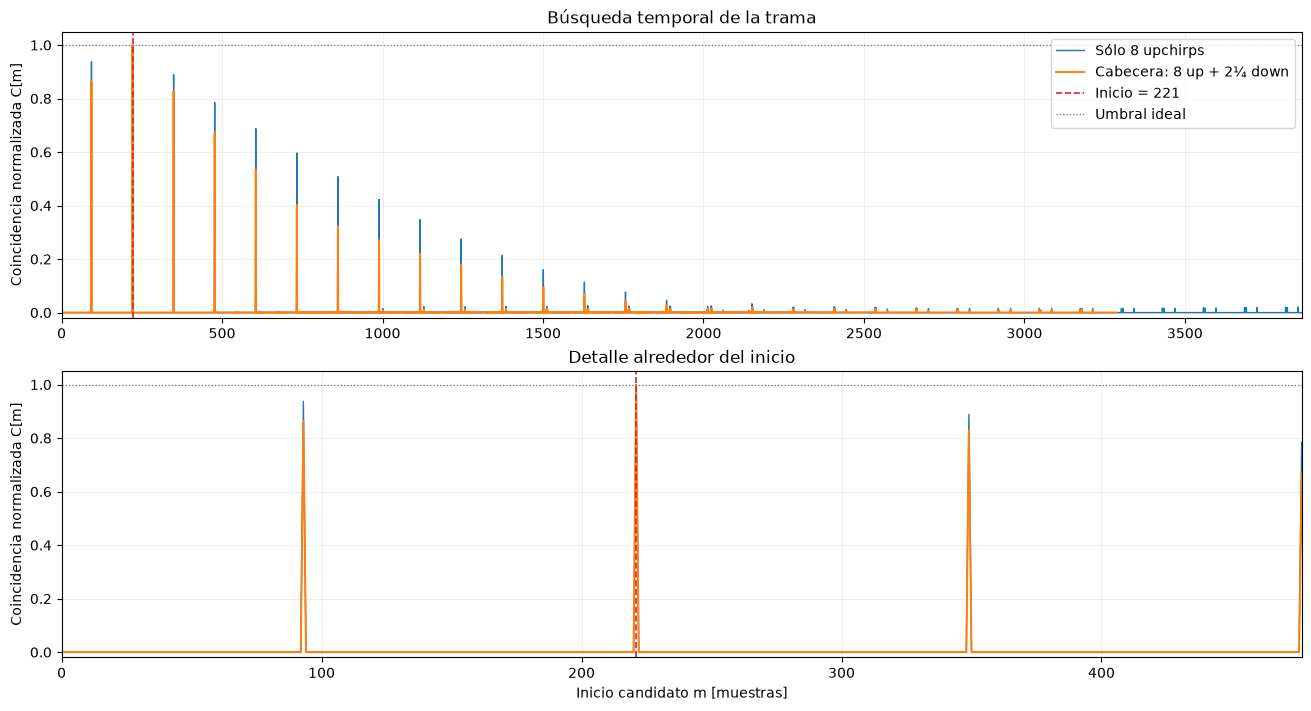

In [7]:
# Comparamos las plantillas y ampliamos el pico para ver cuál identifica el inicio.
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharey=True, constrained_layout=True)
for ax in axes:
    ax.plot(np.arange(len(puntajes_preambulo)), puntajes_preambulo,
            lw=1, color='tab:blue', label='Sólo 8 upchirps')
    ax.plot(np.arange(len(puntajes_cabecera)), puntajes_cabecera,
            lw=1.4, color='tab:orange', label='Cabecera: 8 up + 2¼ down')
    ax.axvline(inicio_detectado, color='tab:red', ls='--', lw=1.2,
               label=f'Inicio = {inicio_detectado}')
    ax.axhline(umbral_ideal, color='0.45', ls=':', lw=0.9, label='Umbral ideal')
    ax.set(ylabel='Coincidencia normalizada C[m]', ylim=(-0.02, 1.05))
    ax.grid(True, alpha=0.2)

axes[0].set(title='Búsqueda temporal de la trama', xlim=(0, len(puntajes_preambulo) - 1))
axes[0].legend(loc='upper right')
axes[1].set(xlabel='Inicio candidato m [muestras]',
            xlim=(max(0, inicio_detectado - N), inicio_detectado + N),
            title='Detalle alrededor del inicio')
plt.show()


La cabecera completa permite distinguir el inicio entre los picos del preámbulo repetido. En la fórmula usada en clase, el upchirp repite su mitad y aparecen picos separados por `N/2`; cada símbolo sigue teniendo `N` muestras.


### 3.2. Leer los 10 bytes del payload sin ruido

Avanzamos la longitud de la cabecera desde el inicio detectado y tomamos **10 bloques consecutivos de `N` muestras**. Aplicamos el helper de dechirp + FFT a cada uno y reunimos los bytes para recuperar `hola mundo`.

Si falta cualquier parte del payload, devolvemos `None`; no evaluamos un mensaje parcial como si estuviera completo.


In [8]:
# Conservamos el helper de demodulación: lo aplicamos una vez por carácter.
def leer_payload(bloque, inicio):
    if inicio is None:
        return None
    inicio_dato = inicio + len(cabecera_conocida)
    payload = bloque[inicio_dato:inicio_dato + longitud_payload]
    if len(payload) != longitud_payload:
        return None
    simbolos_recibidos = payload.reshape(cantidad_caracteres, N)
    return bytes(demodular_simbolo(simbolo)[0] for simbolo in simbolos_recibidos)


payload_recuperado = leer_payload(bloque_recibido, inicio_detectado)
if payload_recuperado is None:
    raise ValueError('Falta la cabecera detectada o el payload completo')
mensaje_recuperado = payload_recuperado.decode('ascii')
bits_recuperados = [f'{valor:08b}' for valor in payload_recuperado]
print(f'Mensaje transmitido: {mensaje!r}')
print(f'Mensaje recuperado:  {mensaje_recuperado!r}')
print(f'Bytes recuperados: {list(payload_recuperado)}')
assert payload_recuperado == payload_transmitido
assert mensaje_recuperado == mensaje and bits_recuperados == bits_payload


Mensaje transmitido: 'hola mundo'
Mensaje recuperado:  'hola mundo'
Bytes recuperados: [104, 111, 108, 97, 32, 109, 117, 110, 100, 111]


### 3.3. Repetir con ruido

Sumamos ruido gaussiano blanco complejo a **todo** el bloque: $r[n]=x[n]+w[n]$. La SNR usa la potencia de la trama activa, sin los ceros. Repetimos la correlación con un umbral manual (`0.01`), porque el puntaje ya no será 1.

*Nota:* dejamos la detección por energía y la calibración de falsas alarmas para otra etapa.


In [9]:
# El umbral es manual: usar el mismo valor no garantiza igual tasa de falsas alarmas.
umbral_ruido = 0.01
potencia_trama = np.mean(np.abs(trama_transmitida) ** 2)


def detectar_payload(bloque, umbral, plantilla=cabecera_conocida,
                     correlador=puntajes_correlacion):
    """Busca el inicio usando la plantilla elegida y luego lee el payload."""
    puntajes = correlador(bloque, plantilla)
    # Ambas plantillas buscan exactamente los mismos inicios candidatos.
    cantidad_inicios = len(bloque) - len(cabecera_conocida) + 1
    puntajes = puntajes[:cantidad_inicios]
    candidato = int(np.argmax(puntajes))
    inicio = candidato if puntajes[candidato] > umbral else None
    # El dato siempre empieza después de la cabecera completa de la trama,
    # incluso cuando para detectar sólo usamos los 8 upchirps.
    return inicio, leer_payload(bloque, inicio), puntajes


SNR: -7 dB | Cmáx: 0.1724 | Inicio: 221 (real: 221) | Mensaje: 'hola mundo' | Paquete correcto: True


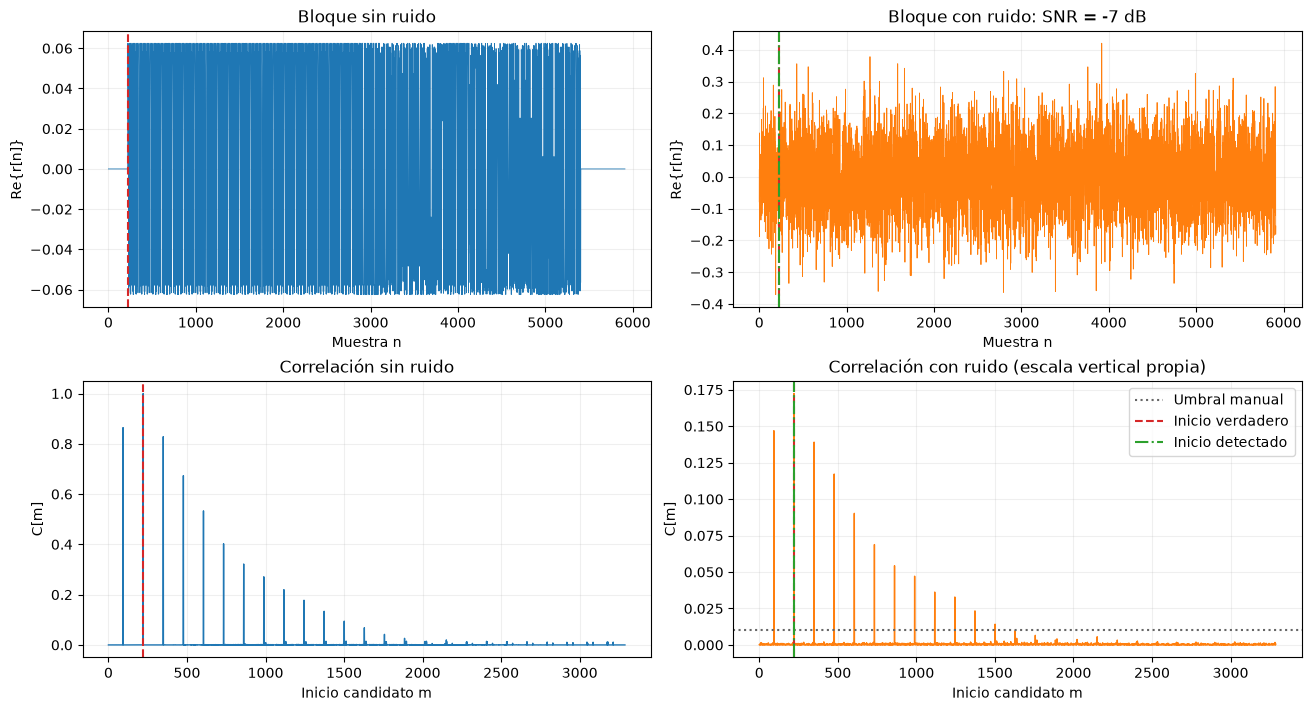

In [10]:
# Sumamos ruido al bloque y comparamos el inicio y el dato con el caso ideal.
snr_ejemplo_db = -7  # volver a ejecutar con otra SNR para comparar
generador_ruido = np.random.default_rng(2026)
potencia_ruido, sigma = parametros_ruido_desde_snr(snr_ejemplo_db, potencia_trama)
bloque_con_ruido, ruido = agregar_ruido_awgn(bloque_recibido, sigma, generador_ruido)

inicio_con_ruido, payload_con_ruido, puntajes_con_ruido = detectar_payload(
    bloque_con_ruido, umbral_ruido)
paquete_correcto = (inicio_con_ruido == inicio_verdadero and payload_con_ruido == payload_transmitido)

mensaje_con_ruido = (payload_con_ruido.decode('ascii', errors='replace')
                    if payload_con_ruido is not None else None)
# La sustitución de caracteres sólo sirve para mostrar el texto; comparamos los bytes originales.
print(f'SNR: {snr_ejemplo_db} dB | Cmáx: {puntajes_con_ruido.max():.4f}'
      f' | Inicio: {inicio_con_ruido} (real: {inicio_verdadero})'
      f' | Mensaje: {mensaje_con_ruido!r} | Paquete correcto: {paquete_correcto}')

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(bloque_recibido.real, lw=0.6)
axes[0, 0].set(title='Bloque sin ruido', ylabel='Re{r[n]}', xlabel='Muestra n')
axes[0, 1].plot(bloque_con_ruido.real, lw=0.6, color='tab:orange')
axes[0, 1].set(title=f'Bloque con ruido: SNR = {snr_ejemplo_db} dB',
               ylabel='Re{r[n]}', xlabel='Muestra n')
axes[1, 0].plot(puntajes_cabecera, lw=1)
axes[1, 0].set(title='Correlación sin ruido', ylabel='C[m]', xlabel='Inicio candidato m')
axes[1, 1].plot(puntajes_con_ruido, lw=1, color='tab:orange')
axes[1, 1].axhline(umbral_ruido, color='0.4', ls=':', label='Umbral manual')
axes[1, 1].set(title='Correlación con ruido (escala vertical propia)',
               ylabel='C[m]', xlabel='Inicio candidato m')
for ax in axes.flat:
    ax.axvline(inicio_verdadero, color='tab:red', ls='--', label='Inicio verdadero')
    ax.grid(True, alpha=0.2)
if inicio_con_ruido is not None:
    for ax in axes[:, 1]:
        ax.axvline(inicio_con_ruido, color='tab:green', ls='-.', label='Inicio detectado')
axes[1, 1].legend()
plt.show()


### 3.4. PER de un payload de 10 bytes frente a SNR

Transmitimos **10 000 paquetes por SNR**, cada uno con el mensaje `hola mundo` y con distintos inicios y ruidos. Un paquete es correcto si **se declara la trama, se ubica su inicio exacto y se recuperan correctamente los 10 bytes**. Basta un carácter incorrecto para que falle el paquete.

| Causa | Condición | Cómo se cuenta |
|---|---|---|
| No se detecta | No hay un pico que supere el umbral | Un paquete fallido |
| Inicio incorrecto | Se declara trama, pero el inicio estimado difiere del verdadero | Un paquete fallido, sin volver a contar su mensaje |
| Payload incorrecto | El inicio es correcto, pero al menos un byte difiere del enviado | Un paquete fallido, aunque haya varios caracteres erróneos |

Los `if / elif` hacen que los casos sean **excluyentes**. El denominador siempre es el número de paquetes transmitidos:

$$\mathrm{PER}=\frac{N_{\mathrm{no\ detectados}}+N_{\mathrm{inicio\ incorrecto}}+
N_{\mathrm{payload\ incorrecto\ con\ inicio\ correcto}}}{K}.$$

Exigimos inicio exacto con tolerancia de cero muestras. La simulación conoce el inicio y el mensaje transmitidos para evaluar los errores; el detector no recibe esas respuestas. Aquí todavía no hay CRC. Las falsas alarmas requieren bloques sin trama y se miden aparte.

**Comparamos dos detectores:** **8 upchirps + 2¼ downchirps** y **sólo 8 upchirps**. La trama conserva los downchirps y ambos receptores leen los 10 bytes después de la cabecera completa. Usan las mismas realizaciones de ruido, el mismo rango de inicios candidatos y el umbral manual `0.01`. Un umbral común no garantiza igual probabilidad de falsa alarma; esa calibración corresponde al análisis de clase 4b.

La tercera curva es una **referencia con inicio conocido**: recortamos el payload desde el inicio verdadero y contamos los paquetes que tienen al menos un byte incorrecto. Es la PER del mensaje completo con sincronización conocida, no una tasa de error de un único símbolo ni BER. Esta referencia no se suma a las otras curvas.

La SNR usa la potencia de la trama activa, sin los márgenes de ceros. La función de correlación original se mantiene paso a paso; en esta sección usamos la variante rápida aparte para repetir los ensayos. Como referencia metodológica, esta [simulación PER de MathWorks](https://www.mathworks.com/help/wlan/ug/802-11ax-packet-error-rate-simulation-for-single-user-format.html) también contabiliza omisiones, fallos de sincronización y payloads incorrectos.


In [11]:
# Esta variante rápida se usa sólo en las repeticiones de PER.
def puntajes_correlacion_per(bloque, plantilla):
    """El mismo puntaje, calculado sin el bucle de Python por ventana."""
    L = len(plantilla)
    if len(bloque) < L:
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    # np.correlate conjuga la plantilla, igual que np.vdot en cada ventana.
    coincidencias = np.correlate(bloque, plantilla, mode='valid')
    energia_acumulada = np.r_[0.0, np.cumsum(np.abs(bloque) ** 2)]
    energias_ventana = energia_acumulada[L:] - energia_acumulada[:-L]
    puntajes = np.zeros(len(coincidencias))
    np.divide(np.abs(coincidencias) ** 2, energia_plantilla * energias_ventana,
              out=puntajes, where=energias_ventana > 0)
    return puntajes


# Comprobamos la equivalencia antes de usarla en la simulación.
for plantilla in (preambulo, cabecera_conocida):
    np.testing.assert_allclose(puntajes_correlacion_per(bloque_recibido, plantilla),
                               puntajes_correlacion(bloque_recibido, plantilla),
                               atol=1e-12, rtol=1e-12)

# Los dos detectores ven cada misma realización de señal, inicio y ruido.
snrs_db = np.array([-30, -25, -20, -18, -15, -12, -10, -5, 0])
paquetes_por_snr = 50000
generador_per = np.random.default_rng(2027)
plantillas_per = {
    'Cabecera completa': cabecera_conocida,
    'Sólo 8 upchirps': preambulo,
}
resultados_per = {nombre: [] for nombre in plantillas_per}
conteos_causas_per = {nombre: [] for nombre in plantillas_per}
per_inicio_conocido = []

print(' SNR  Detector            No detecta  Inicio mal  Payload mal  Errores/K       PER   PER inicio conocido')
for snr_db in snrs_db:
    _, sigma_per = parametros_ruido_desde_snr(snr_db, potencia_trama)
    conteos = {nombre: np.zeros(3, dtype=int) for nombre in plantillas_per}
    errores_referencia = 0

    for _ in range(paquetes_por_snr):
        inicio_real = int(2 * generador_per.integers(0, N) + 1)
        bloque_limpio = np.concatenate((
            np.zeros(inicio_real, dtype=complex), trama_transmitida,
            np.zeros(2 * N - inicio_real, dtype=complex)))
        recibido, _ = agregar_ruido_awgn(bloque_limpio, sigma_per, generador_per)

        # La referencia conoce el inicio; no interviene en ningún detector.
        errores_referencia += int(leer_payload(recibido, inicio_real) != payload_transmitido)

        for nombre, plantilla in plantillas_per.items():
            inicio_estimado, dato_estimado, _ = detectar_payload(
                recibido, umbral_ruido, plantilla, correlador=puntajes_correlacion_per)
            # Clasificación excluyente: cada paquete fallido se cuenta una sola vez.
            if inicio_estimado is None:
                conteos[nombre][0] += 1
            elif inicio_estimado != inicio_real:
                conteos[nombre][1] += 1
            elif dato_estimado != payload_transmitido:
                conteos[nombre][2] += 1

    per_referencia = errores_referencia / paquetes_por_snr
    per_inicio_conocido.append(per_referencia)
    for nombre in plantillas_per:
        no_detectados, inicios_erroneos, datos_erroneos = conteos[nombre]
        errores = int(conteos[nombre].sum())
        per = errores / paquetes_por_snr
        resultados_per[nombre].append(per)
        conteos_causas_per[nombre].append(conteos[nombre].copy())
        # Con el mismo ruido, acertar inicio y payload implica acertar la referencia.
        assert 0 <= per_referencia <= per <= 1
        print(f'{snr_db:4.0f}  {nombre:<18} {no_detectados:10d} {inicios_erroneos:11d}'
              f' {datos_erroneos:9d} {errores:5d}/{paquetes_por_snr:<4d}'
              f' {per:9.2e} {per_referencia:20.2e}')

resultados_per = {nombre: np.asarray(valores) for nombre, valores in resultados_per.items()}
conteos_causas_per = {nombre: np.asarray(valores) for nombre, valores in conteos_causas_per.items()}
per_inicio_conocido = np.asarray(per_inicio_conocido)
for nombre in plantillas_per:
    np.testing.assert_allclose(
        conteos_causas_per[nombre].sum(axis=1) / paquetes_por_snr, resultados_per[nombre])


 SNR  Detector            No detecta  Inicio mal  Payload mal  Errores/K       PER   PER inicio conocido
 -30  Cabecera completa       50000           0         0 50000/50000  1.00e+00             1.00e+00
 -30  Sólo 8 upchirps         49997           2         1 50000/50000  1.00e+00             1.00e+00
 -25  Cabecera completa       49941          17        42 50000/50000  1.00e+00             1.00e+00
 -25  Sólo 8 upchirps         49778         101       121 50000/50000  1.00e+00             1.00e+00
 -20  Cabecera completa       23792        2530     23678 50000/50000  1.00e+00             1.00e+00
 -20  Sólo 8 upchirps         22894        6785     20321 50000/50000  1.00e+00             1.00e+00
 -18  Cabecera completa        1373        2462     46164 49999/50000  1.00e+00             1.00e+00
 -18  Sólo 8 upchirps          1957        8167     39875 49999/50000  1.00e+00             1.00e+00
 -15  Cabecera completa           0         300     47244 47544/50000  9.51e-01        

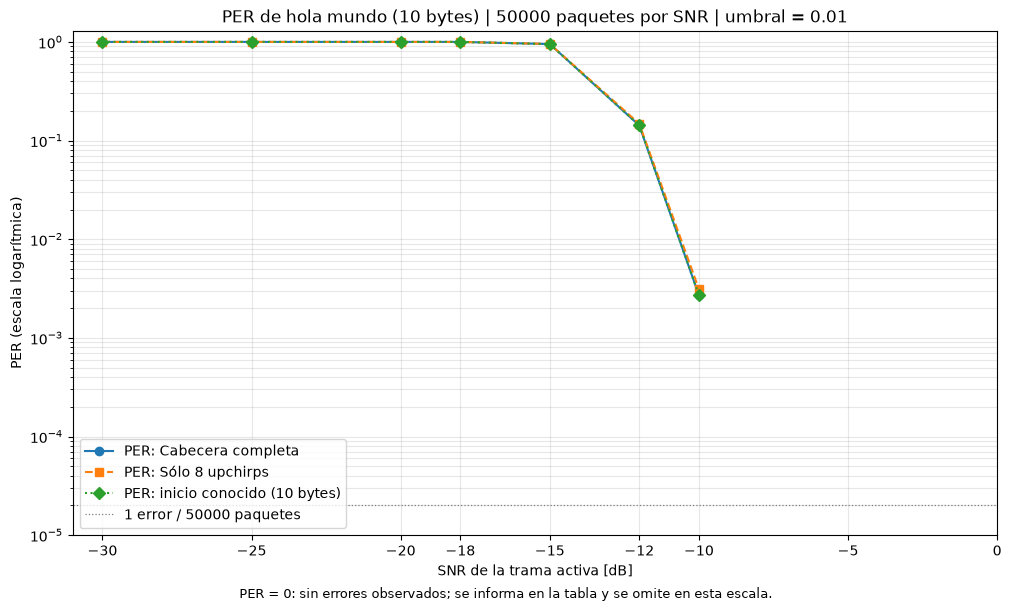

In [12]:
# Tres curvas de PER: dos receptores y una referencia de sincronización conocida.
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for (nombre, per), estilo in zip(resultados_per.items(), ('o-', 's--')):
    # NaN oculta los ceros y evita unir puntos a través de ellos.
    ax.semilogy(snrs_db, np.where(per > 0, per, np.nan), estilo,
                lw=1.5, label=f'PER: {nombre}')
ax.semilogy(snrs_db, np.where(per_inicio_conocido > 0, per_inicio_conocido, np.nan),
            'D:', color='tab:green', lw=1.5, label='PER: inicio conocido (10 bytes)')
ax.axhline(1 / paquetes_por_snr, color='0.5', ls=':', lw=0.9,
           label=f'1 error / {paquetes_por_snr} paquetes')
ax.set(xlabel='SNR de la trama activa [dB]', ylabel='PER (escala logarítmica)',
       title=f'PER de hola mundo (10 bytes) | {paquetes_por_snr} paquetes por SNR | umbral = {umbral_ruido}',
       ylim=(0.5 / paquetes_por_snr, 1.3))
ax.set_xticks(snrs_db)
ax.grid(True, which='both', alpha=0.3)
ax.legend(loc='lower left')
fig.supxlabel('PER = 0: sin errores observados; se informa en la tabla y se omite en esta escala.',
              fontsize=9)
plt.show()


**Cómo leer las curvas.** Un punto en $10^{-2}$ significa que falló aproximadamente el 1 % de los paquetes de 10 bytes. Las dos primeras curvas exigen detección, inicio exacto y mensaje completo correcto; la referencia evalúa los 10 bytes con sincronización conocida. Las curvas no se suman entre sí.

Una PER de cero significa cero errores observados en esos ensayos, no una probabilidad real necesariamente nula. Con **10 000 paquetes**, un único error representa $10^{-4}$. Los ceros se conservan en la tabla y se omiten en la escala logarítmica.

Un paquete se cuenta una sola vez aunque tenga varios bytes o bits incorrectos. Por eso esta curva no es BER. Mantener el mismo mensaje permite estudiar el cambio de longitud del payload; los resultados corresponden a este mensaje y a este modelo AWGN con SF=8.


### 3.5. ¿Por qué fallan los paquetes de 10 bytes?

Cada barra apila las **tres causas excluyentes** del contador. Su altura total es la PER del receptor para esa SNR. El eje vertical es lineal para mostrar ceros y sumar las partes; los colores tienen el mismo significado en ambos paneles.

La parte de «payload incorrecto» sólo cuenta paquetes cuyo inicio fue correcto. La referencia con inicio conocido, en cambio, examina el mensaje en **todos** los paquetes. Evaluamos AWGN con umbral manual, sin desajustes de frecuencia o reloj.


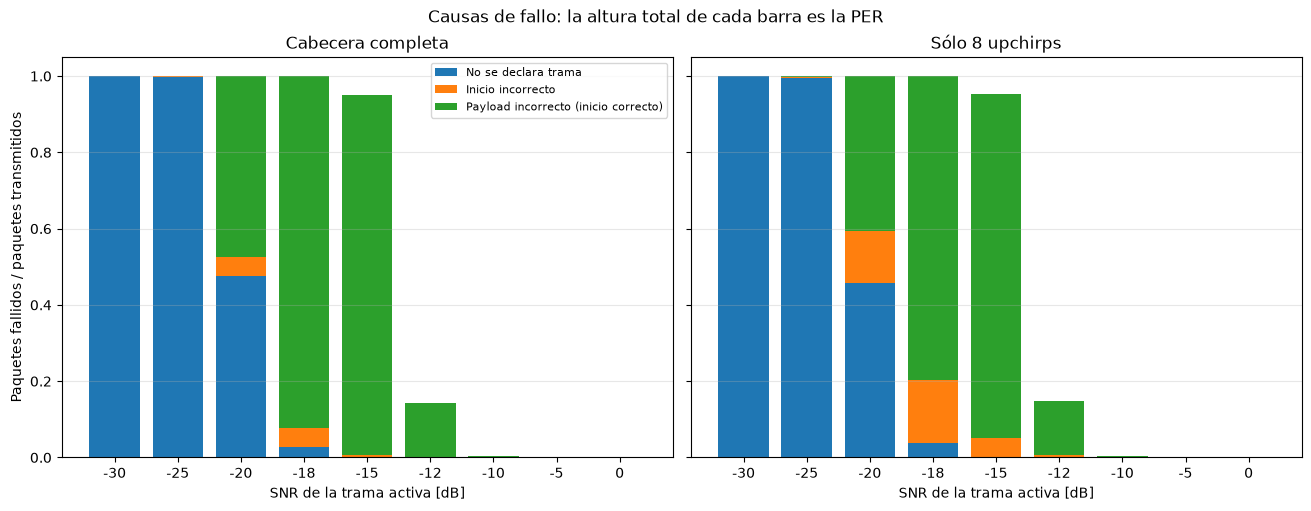

In [13]:
# Cada segmento es un número de fallos dividido por los K paquetes transmitidos.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
etiquetas_causas = ('No se declara trama', 'Inicio incorrecto', 'Payload incorrecto (inicio correcto)')
colores_causas = ('tab:blue', 'tab:orange', 'tab:green')
posiciones = np.arange(len(snrs_db))
for ax, nombre in zip(axes, plantillas_per):
    fracciones = conteos_causas_per[nombre] / paquetes_por_snr
    base = np.zeros(len(snrs_db))
    for j, (etiqueta, color) in enumerate(zip(etiquetas_causas, colores_causas)):
        ax.bar(posiciones, fracciones[:, j], bottom=base, color=color, label=etiqueta)
        base += fracciones[:, j]
    ax.set(title=nombre, xlabel='SNR de la trama activa [dB]', ylim=(0, 1.05))
    ax.set_xticks(posiciones, [f'{snr:g}' for snr in snrs_db])
    ax.grid(True, axis='y', alpha=0.3)
axes[0].set_ylabel('Paquetes fallidos / paquetes transmitidos')
axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle('Causas de fallo: la altura total de cada barra es la PER')
plt.show()
